# Model M0: which installations to verify, and when to withhold

M0 decides, for one compliance year, which installations in a precursor tree to have verified. Verifying node *i* costs c<sub>i</sub> and succeeds with probability ρ<sub>i</sub>. On success the installation's actual emissions θ<sub>i</sub> are revealed, and the exporter either **uses** them (and may go on to verify that node's own suppliers) or **withholds** them (the node and everything upstream stay on default values).

The value of the option to verify a node is computed from the leaves up:

V<sub>i</sub> = max{ 0, −c<sub>i</sub> + ρ<sub>i</sub> · E[ max{ 0, B<sub>i</sub>(K<sub>i</sub> − θ<sub>i</sub>) + Σ<sub>j</sub> V<sub>j</sub> } ] }

Here B<sub>i</sub>(K<sub>i</sub> − θ) is the euro saving from using node *i*'s data, and the sum runs over its suppliers. The optimal plan is **verify *i* if V<sub>i</sub> > 0, and use the result only if θ<sub>i</sub> is below a threshold k<sub>i</sub>**. With lognormal beliefs the expectation has a closed form, so each tree is solved exactly in a fraction of a millisecond.

The M0 plan is compared with four alternatives:

- **static commitment**: the same tree recursion, but every result is used (no withholding);
- **myopic**: a node is verified only if its own expected saving covers its cost;
- **verify all**: verify every node and use every result;
- **perfect information**: an upper bound in which θ is known before deciding.

Values are expected net savings in euros per year, relative to declaring everything on defaults. Assumptions are the central ones in `Data/parameters/` (futures prices, supplier coefficient of variation 0.25, success probability 0.9, full pass-through).

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 30, "display.width", 200)

print(subprocess.run([sys.executable, "scripts/run_m0.py"], cwd=ROOT, capture_output=True, text=True, check=True).stdout)
base = pd.read_csv(ROOT / "Data/results/m0_base.csv")
plans = pd.read_csv(ROOT / "Data/results/m0_plans.csv")
sweeps = pd.read_csv(ROOT / "Data/results/m0_sweeps.csv")

M0 solved for 4 trees x 9 years; 264 sweep runs; slowest single solve 0.05 ms
  T1 2026: M0 EUR   4,589,924 | static   4,584,164 | myopic           0 | all   4,584,164 | perfect   4,590,898 | verify: M1 M2 R
  T1 2028: M0 EUR   7,963,434 | static   7,962,623 | myopic           0 | all   7,962,623 | perfect   7,964,488 | verify: M1 M2 R
  T1 2030: M0 EUR   8,388,392 | static   8,387,515 | myopic           0 | all   8,387,515 | perfect   8,391,888 | verify: M1 M2 R
  T2 2026: M0 EUR           0 | static           0 | myopic           0 | all  -3,535,193 | perfect     144,998 | verify: none
  T2 2028: M0 EUR      15,323 | static           0 | myopic           0 | all    -774,675 | perfect   1,169,271 | verify: PEL DRI PIG R
  T2 2030: M0 EUR   1,420,016 | static     583,118 | myopic           0 | all     583,118 | perfect   2,005,626 | verify: PEL DRI PIG R
  T3 2026: M0 EUR   2,539,125 | static   2,372,998 | myopic           0 | all   2,372,998 | perfect   2,561,793 | verify: EAF BF R
  

## 1. Value of the M0 plan against the alternatives (EUR thousand per year)

In [2]:
cols = ["value_m0", "value_static", "value_myopic", "value_verify_all", "value_perfect_info"]
t = base[base.year.isin([2026, 2028, 2030, 2034])].set_index(["tree", "year"])[cols + ["withhold_option_value", "gap_to_perfect_info_pct", "nodes_verified"]].copy()
t[cols + ["withhold_option_value"]] = (t[cols + ["withhold_option_value"]] / 1000).round(0).astype(int)
t.columns = ["M0", "static", "myopic", "verify all", "perfect info", "withhold option", "gap to perfect info %", "verified"]
t

M0  static  myopic  verify all  perfect info  withhold option  gap to perfect info %       verified
tree year                                                                                                       
T1   2026  4590    4584       0        4584          4591                6                    0.0        M1 M2 R
     2028  7963    7963       0        7963          7964                1                    0.0        M1 M2 R
     2030  8388    8388       0        8388          8392                1                    0.0        M1 M2 R
     2034  8255    8254       0        8254          8253                1                    0.0        M1 M2 R
T2   2026     0       0       0       -3535           145                0                  100.0           none
     2028    15       0       0        -775          1169               15                   98.7  PEL DRI PIG R
     2030  1420     583       0         583          2006              837                   29.2  PEL DRI PIG R
     2034  3303    2458       0        2458          3326              845                    0.7  PEL DRI PIG R
T3   2026  2539    2373       0        2373          2562              166                    0.9       EAF BF R
     2028  5031    4970       0        4970          5038               62                    0.1       EAF BF R
     2030  6295    6228       0        6228          6303               66                    0.1       EAF BF R
     2034  7535    7468       0        7468          7545               68                    0.1       EAF BF R
T4   2026  1808    1781    1781        1781          1822               27                    0.8      PRI SEC R
     2028  2975    2967    2967        2967          2979                8                    0.1      PRI SEC R
     2030  3302    3293    3293        3293          3306                9                    0.1      PRI SEC R
     2034  3473    3464    3464        3464          3477                9                    0.1      PRI SEC R

- In all three steel trees the exporter's own installation is expected to *add* certificates when verified alone, so the myopic rule never starts and captures nothing. M0 verifies the exporter's own installation anyway, because that is what lets the suppliers' data count.
- The withhold option is worth most where defaults are close to expected actuals. It is worth very little in T1, where China's defaults are far above plant estimates and results are almost always used. In T2 (India, 2030) it is worth more than half of the M0 value.
- In T2, nothing is worth verifying in 2026 or 2027. Verification starts in 2028 and grows as the CBAM factor phases out the deduction that the default path enjoys.
- M0 is close to the perfect-information bound except in T2, where knowing emissions in advance would be worth much more. Better pre-verification estimates (for example, supplier self-reports) would have value there.

## 2. The plans in 2026 (and T2 in 2030)

In [3]:
show = plans[((plans.year == 2026) & (plans.tree != "T2")) | ((plans.year == 2030) & (plans.tree == "T2"))].copy()
show["node"] = ["  " * d + n for d, n in zip(show.depth, show.node)]
show = show[["tree", "year", "node", "verify", "theta_mean", "use_if_theta_below", "p_used", "own_expected_gain_eur", "option_value_eur"]]
show.columns = ["tree", "year", "node", "verify", "θ mean", "use if θ below", "P(used)", "own expected gain €", "option value €"]
show.set_index(["tree", "year", "node"])

verify  θ mean  use if θ below  P(used)  own expected gain €  option value €
tree year node                                                                                 
T1   2026 R          True    0.02          1.3422    0.900              -364655         4589924
            M1       True    1.95          3.5181    0.805              3319212         3323052
            M2       True    1.95          3.5181    0.805              2179475         2182035
T2   2030 R          True    0.13          0.4538    0.900             -2007425         1420016
            DRI      True    4.33          4.9816    0.612              2180331         3593145
              PEL    True    0.34          0.4420    0.486               576203          617649
            PIG      True    2.74          3.2750    0.649               179467          215122
T3   2026 R          True    0.05          0.7852    0.900              -106793         2539125
            EAF      True    0.19          1.4432    0.810              2177125         2177125
            BF       True    2.31          2.6832    0.622               578198          762784
T4   2026 R          True    0.25          2.8796    0.900              1245995         1807701
            PRI      True    2.59          3.3000    0.701               247328          277431
            SEC      True    0.30          2.0013    0.810               346686          346686

Reading the T2 rows for 2030: the DRI plant is verified and its result is used only if its emissions come out below 4.98 t CO₂ per t DRI (mean 4.33). Its pellet and pig-iron suppliers are verified only after that. The billet maker's own expected gain is about −€2.0 million, yet its option value is +€1.4 million.

## 3. Value by year

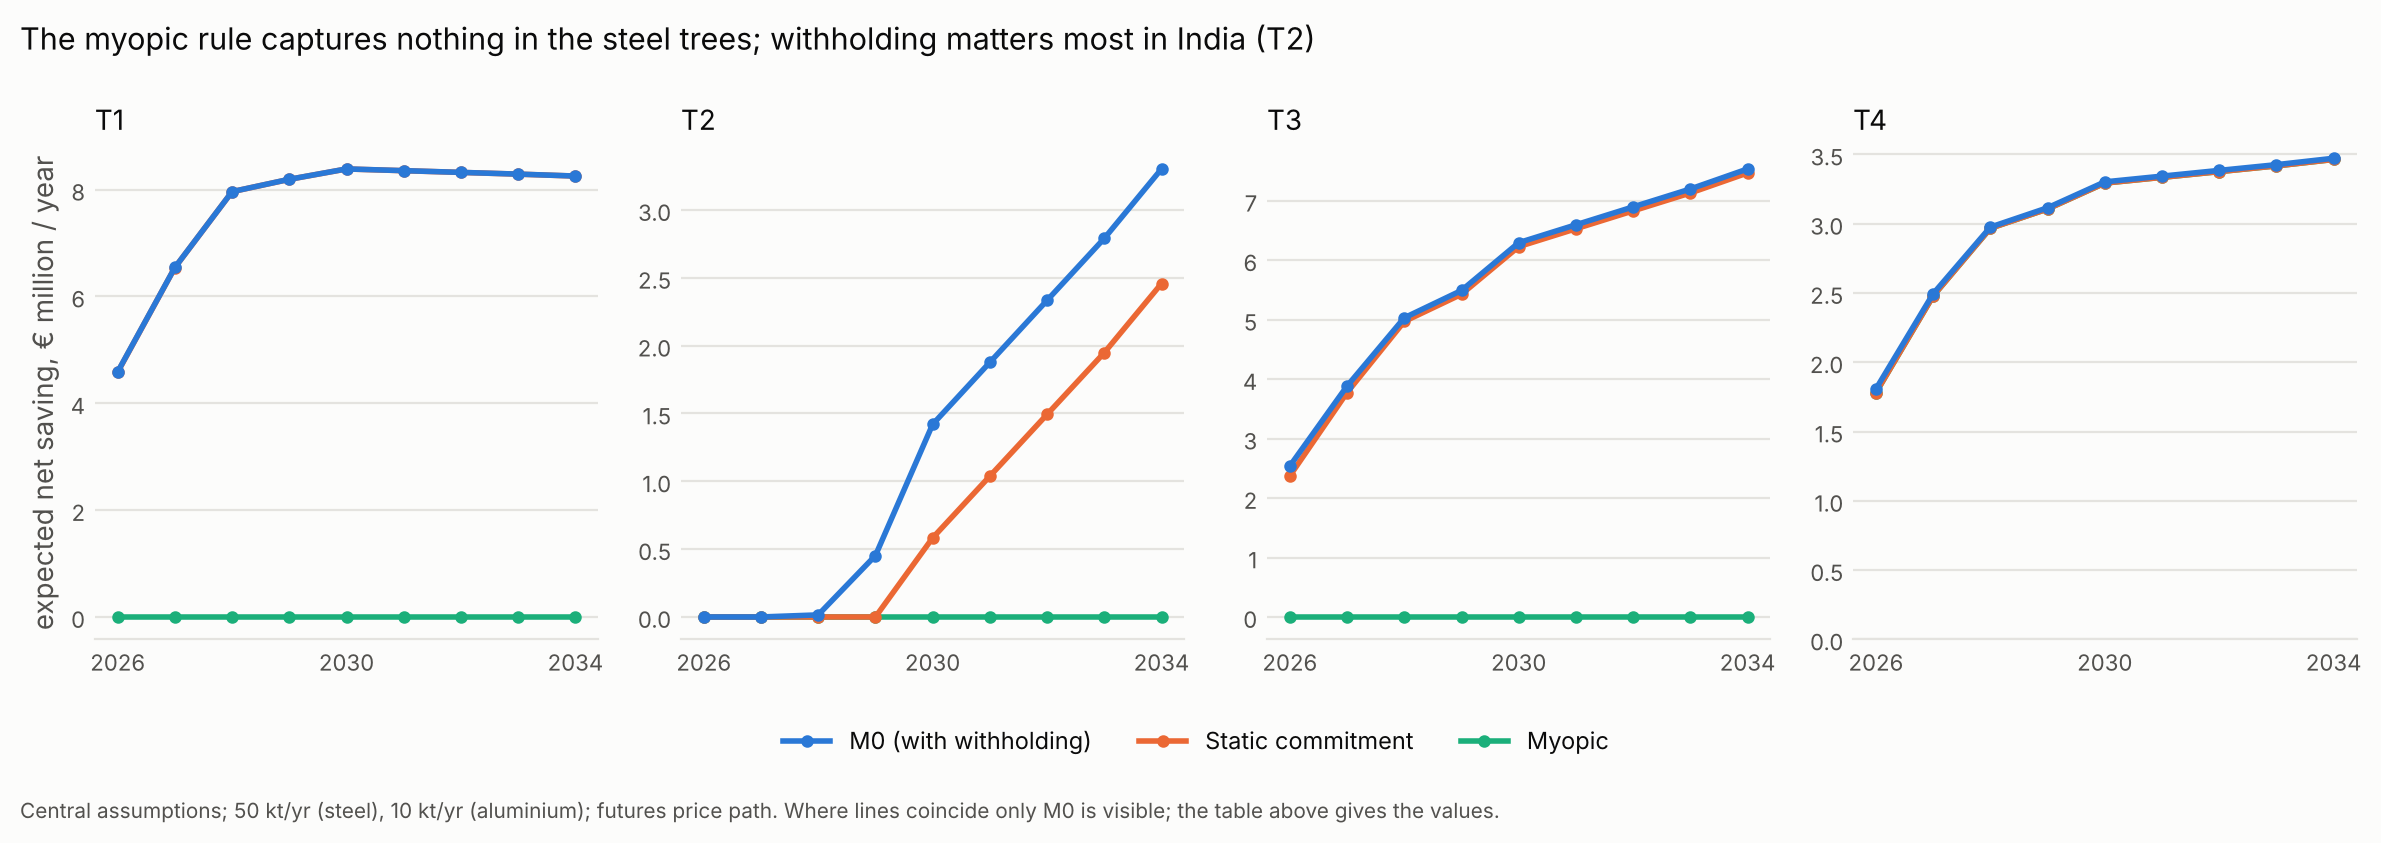

In [4]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
# M0 last, on top
SERIES = [("value_myopic", "Myopic", "#1baf7a"),
          ("value_static", "Static commitment", "#eb6834"),
          ("value_m0", "M0 (with withholding)", "#2a78d6")]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), facecolor=SURFACE)
for ax, (tid, g) in zip(axes, base.groupby("tree")):
    ax.set_facecolor(SURFACE)
    for col, label, color in SERIES:
        ax.plot(g.year, g[col] / 1e6, color=color, lw=2, marker="o", ms=3.5, label=label)
    ax.set_title(tid, loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=8)
    ax.set_xticks([2026, 2030, 2034]); ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
axes[0].set_ylabel("expected net saving, € million / year", color=INK2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], frameon=False, fontsize=8.5, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.1), labelcolor=INK)
fig.suptitle("The myopic rule captures nothing in the steel trees; withholding matters most in India (T2)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.text(0.01, -0.16, "Central assumptions; 50 kt/yr (steel), 10 kt/yr (aluminium); futures price path. Where lines coincide only M0 is visible; the table above gives the values.",
         fontsize=7.5, color=INK2)
fig.tight_layout(); plt.show()

## 4. Value of the withhold option against the supplier spread

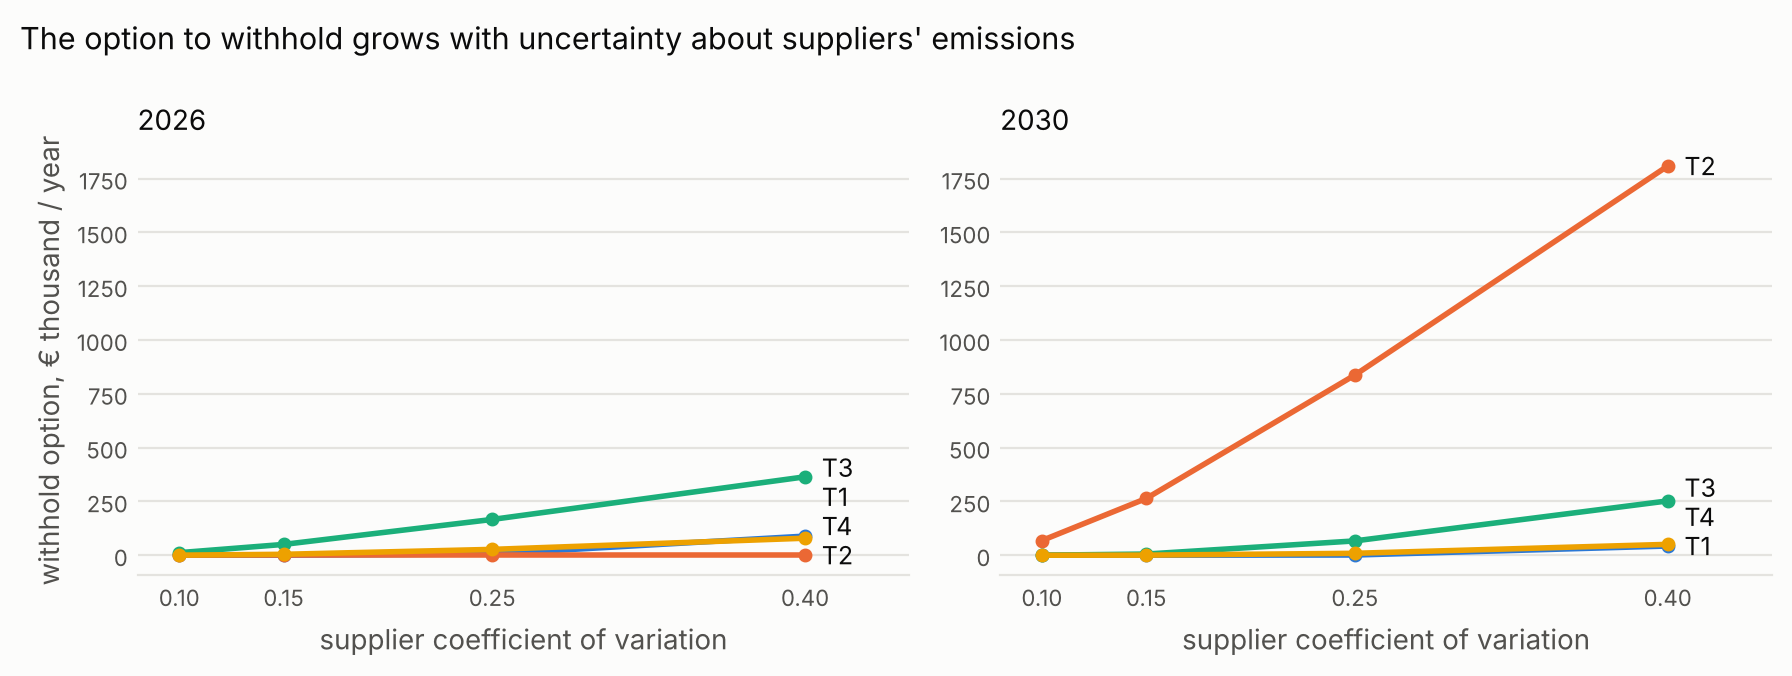

In [5]:
PAL = {"T1": "#2a78d6", "T2": "#eb6834", "T3": "#1baf7a", "T4": "#eda100"}
cv = sweeps[sweeps.factor == "supplier_cv"].copy()
cv["level"] = cv.level.astype(float)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, facecolor=SURFACE)
for ax, year in zip(axes, [2026, 2030]):
    ax.set_facecolor(SURFACE)
    ends = []
    for tid, g in cv[cv.year == year].groupby("tree"):
        ax.plot(g.level, g.withhold_option_value / 1e3, color=PAL[tid], lw=2, marker="o", ms=4)
        ends.append([g.withhold_option_value.iloc[-1] / 1e3, tid])
    # end labels, nudged apart
    ends.sort()
    gap = 0.075 * cv.withhold_option_value.max() / 1e3     # panels share the y axis
    for k in range(1, len(ends)):
        ends[k][0] = max(ends[k][0], ends[k - 1][0] + gap)
    for yv, tid in ends:
        ax.annotate(tid, (0.408, yv), fontsize=9, color=INK, va="center")
    ax.set_title(str(year), loc="left", fontsize=10, color=INK)
    ax.set_xlabel("supplier coefficient of variation", color=INK2)
    ax.set_xticks([0.10, 0.15, 0.25, 0.40]); ax.set_xlim(0.08, 0.45)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=8)
axes[0].set_ylabel("withhold option, € thousand / year", color=INK2)
axes[1].tick_params(labelleft=True)
fig.suptitle("The option to withhold grows with uncertainty about suppliers' emissions", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); plt.show()

## 5. Sensitivity (EUR thousand per year, M0 value)

In [6]:
s = sweeps[sweeps.year.isin([2026, 2030])].copy()
s["value"] = (s.value_m0 / 1000).round(0).astype(int)
out = s.pivot_table(index=["factor", "level"], columns=["tree", "year"], values="value", aggfunc="first")
out

tree                               T1            T2               T3               T4         
year                             2026     2030 2026    2030     2026     2030    2026     2030
factor              level                                                                     
cost_scale          0.5        4695.0   8493.0  0.0  1462.0   2644.0   6400.0  1872.0   3367.0
                    1.0        4590.0   8388.0  0.0  1420.0   2539.0   6295.0  1808.0   3302.0
                    2.0        4380.0   8178.0  0.0  1336.0   2329.0   6085.0  1679.0   3173.0
pass_through        0.25        990.0   1940.0  0.0   292.0    477.0   1416.0   360.0    729.0
                    0.5        2190.0   4089.0  0.0   668.0   1165.0   3042.0   839.0   1587.0
                    1.0        4590.0   8388.0  0.0  1420.0   2539.0   6295.0  1808.0   3302.0
price_scenario      flat       4590.0   6500.0  0.0  1090.0   2539.0   4866.0  1808.0   2549.0
                    futures    4590.0   8388.0  0.0  1420.0   2539.0   6295.0  1808.0   3302.0
                    high       4590.0  12752.0  0.0  2184.0   2539.0   9596.0  1808.0   5044.0
success_probability 0.6        1909.0   3533.0  0.0   109.0   1055.0   2695.0  1048.0   1869.0
                    0.9        4590.0   8388.0  0.0  1420.0   2539.0   6295.0  1808.0   3302.0
                    1.0        5737.0  10462.0  0.0  2063.0   3173.0   7826.0  2093.0   3852.0
supplier_cv         0.1        4584.0   8388.0  0.0   651.0   2385.0   6229.0  1781.0   3293.0
                    0.15       4584.0   8388.0  0.0   847.0   2423.0   6234.0  1785.0   3294.0
                    0.25       4590.0   8388.0  0.0  1420.0   2539.0   6295.0  1808.0   3302.0
                    0.4        4673.0   8430.0  0.0  2392.0   2737.0   6481.0  1860.0   3344.0
volume_t            1000.0        NaN      NaN  NaN     NaN      NaN      NaN   121.0    229.0
                    10000.0     750.0   1510.0  0.0   217.0    340.0   1091.0  1808.0   3302.0
                    100000.0   9390.0  16987.0  0.0  2924.0   5288.0  12800.0     NaN      NaN
                    2000.0        NaN      NaN  NaN     NaN      NaN      NaN   280.0    557.0
                    25000.0    2190.0   4089.0  0.0   668.0   1165.0   3042.0  4713.0   8449.0
                    250000.0  23790.0  42782.0  0.0  7438.0  13536.0  32314.0     NaN      NaN
                    5000.0      270.0    650.0  0.0    66.0     77.0    440.0   839.0   1587.0
                    50000.0    4590.0   8388.0  0.0  1420.0   2539.0   6295.0  9555.0  17027.0

In [7]:
# Which nodes are verified at each volume (2026)
v = sweeps[(sweeps.factor == "volume_t") & (sweeps.year == 2026)]
v.pivot_table(index="level", columns="tree", values="nodes_verified", aggfunc="first")

tree,T1,T2,T3,T4
level,,,,
1000.0,NaN,NaN,NaN,SEC R
10000.0,M1 M2 R,none,EAF BF R,PRI SEC R
100000.0,M1 M2 R,none,EAF BF R,NaN
2000.0,NaN,NaN,NaN,SEC R
25000.0,M1 M2 R,none,EAF BF R,PRI SEC R
250000.0,M1 M2 R,none,EAF BF R,NaN
5000.0,M1 M2 R,none,EAF R,PRI SEC R
50000.0,M1 M2 R,none,EAF BF R,PRI SEC R


## Checks and caveats

- `tests/test_m0.py` compares the closed-form expectation with simulation and the M0 value with an exact evaluation and a simulation of its own plan. It also checks the ordering static ≤ M0 ≤ perfect information, that M0 equals static when there is no uncertainty, and that no plan on a brute-force grid, and no small change to the M0 plan, does better.
- **Zero floor.** Certificates cannot go below zero; the recursion ignores this floor. Simulating the M0 plan with the floor applied changes its value by less than 0.5% in every tree and year (`sim_value_m0_with_floor` in `m0_base.csv`).
- **Scope.** M0 treats each year on its own. Set-up costs, carrying verified data across years and the timing of when to start belong to M1. Verifier capacity belongs to M2.
- **Legal assumption.** The withhold option assumes a declarant may keep using default values after receiving an unfavourable verified result. This is still an open legal question, and the static-commitment column shows the value without it.